In [ ]:
# Anti-reflection coatings for silicon solar cells

Bare silicon reflects about a third of incoming sunlight, which is a direct loss for a solar cell.
In this project I design and optimize single- and double-layer anti-reflection coatings using the
transfer-matrix method with measured optical constants. I also implement the transfer-matrix
method myself, weight the results by the solar spectrum, and check the performance at oblique angles.

In [64]:
import numpy as np, matplotlib.pyplot as plt
from tmm import coh_tmm, absorp_in_each_layer
from scipy.optimize import minimize_scalar, minimize
from pvlib.spectrum import get_reference_spectra

In [ ]:
## 1. First approximation

As a starting point I use constant refractive indices (Si: 3.9, Si3N4: 2.0) and a 75 nm coating,
chosen from the quarter-wave condition $d = \lambda / 4n$ at 600 nm.

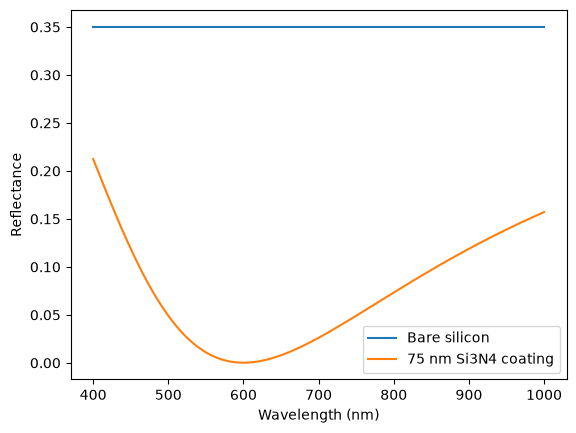

In [65]:
wl = np.linspace(400, 1000, 300)  # wavelength in nm
R_bare = [coh_tmm('s', [1, 3.9], [np.inf, np.inf], 0, w)['R'] for w in wl]
R_arc = [coh_tmm('s', [1, 2.0, 3.9], [np.inf, 75, np.inf], 0, w)['R'] for w in wl]
plt.plot(wl, R_bare, label='Bare silicon'); plt.plot(wl, R_arc, label='75 nm Si3N4 coating')
plt.xlabel('Wavelength (nm)'); plt.ylabel('Reflectance'); plt.legend(); plt.show()

In [ ]:
## 2. Material data

Optical constants are taken from refractiveindex.info: Si (Green 2008, n and k), Si3N4 (Luke et al. 2015),
SiO2 (Malitson 1965) and TiO2 (Zhukovsky et al. 2015, thin film, n and k). The data are interpolated
onto the simulation wavelength grid (400–1000 nm). Absorbing materials are described by a complex
refractive index $\tilde{n} = n + ik$.

In [66]:
data = np.loadtxt('data/Si3N4_Luke2015.csv', delimiter=',', skiprows=1)
wl_um, n_data = data[:, 0], data[:, 1]

def n_SiN(wl_nm):
    return np.interp(wl_nm / 1000, wl_um, n_data)

print(n_SiN(600))

2.0441649978839833


In [67]:
def load_nk(filename):
    text = open(filename).read()
    n_part, k_part = text.split('wl,k')
    n_data = np.loadtxt(n_part.splitlines()[1:], delimiter=',')
    k_data = np.loadtxt(k_part.splitlines()[1:], delimiter=',')
    return n_data, k_data

si_n, si_k = load_nk('data/Si_Green2008.csv')

def n_Si(wl_nm):
    wl_um = wl_nm / 1000
    return np.interp(wl_um, si_n[:, 0], si_n[:, 1]) + 1j * np.interp(wl_um, si_k[:, 0], si_k[:, 1])

print(n_Si(600))

(3.94+0.019934j)


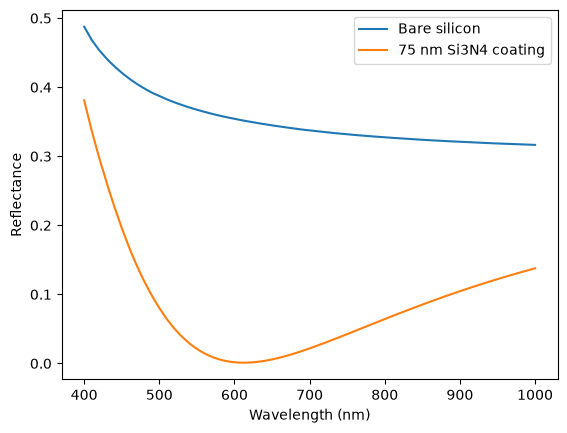

In [68]:
wl = np.linspace(400, 1000, 300)  # wavelength in nm
R_bare = [coh_tmm('s', [1, n_Si(w)], [np.inf, np.inf], 0, w)['R'] for w in wl]
R_arc = [coh_tmm('s', [1, n_SiN(w), n_Si(w)], [np.inf, 75, np.inf], 0, w)['R'] for w in wl]
plt.plot(wl, R_bare, label='Bare silicon'); plt.plot(wl, R_arc, label='75 nm Si3N4 coating')
plt.xlabel('Wavelength (nm)'); plt.ylabel('Reflectance'); plt.legend(); plt.show()

In [ ]:
## 3. Single-layer Si3N4 coating

I optimize the Si3N4 thickness to minimize the average reflectance over 400–1000 nm.
The optimum (72.7 nm) is very close to the quarter-wave estimate, and reduces the average
reflectance from 35.2% (bare Si) to 8.2%. The tolerance plot shows a flat minimum, so a few nm
of thickness error barely matter, which is important for manufacturing.

In [69]:
def avg_R(d):
    return np.mean([coh_tmm('s', [1, n_SiN(w), n_Si(w)], [np.inf, d, np.inf], 0, w)['R'] for w in wl])

res = minimize_scalar(avg_R, bounds=(20, 200), method='bounded')
print(f"Optimal thickness: {res.x:.1f} nm, average R: {res.fun:.3f}")
print(f"Your 75 nm guess: average R: {avg_R(75):.3f}")

Optimal thickness: 72.7 nm, average R: 0.082
Your 75 nm guess: average R: 0.083


In [70]:
R_bare_avg = np.mean([coh_tmm('s', [1, n_Si(w)], [np.inf, np.inf], 0, w)['R'] for w in wl])
print(f"Bare silicon average R: {R_bare_avg:.3f}")

Bare silicon average R: 0.352


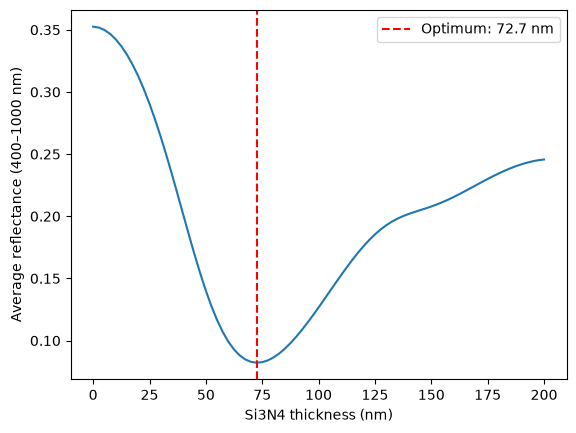

In [71]:
d_values = np.linspace(0, 200, 81)
R_values = [avg_R(d) for d in d_values]
plt.plot(d_values, R_values)
plt.axvline(res.x, color='red', linestyle='--', label=f'Optimum: {res.x:.1f} nm')
plt.xlabel('Si3N4 thickness (nm)'); plt.ylabel('Average reflectance (400–1000 nm)')
plt.legend(); plt.show()

In [ ]:
## 4. Double-layer coatings

### SiO2/Si3N4
A second, lower-index layer on top (SiO2) gives a more gradual index transition from air to silicon.
The optimized design (95.3/67.8 nm) reduces the average reflectance to 5.7%, but the spectrum shows
a reflection bump of about 11% around 550 nm.

This bump follows from thin-film theory. For two quarter-wave layers, the reflectance at the
center wavelength is

$$R = \left(\frac{n_2^2 - n_s n_1^2}{n_2^2 + n_s n_1^2}\right)^2$$

which gives about 11% for SiO2/Si3N4 on Si. Zero reflectance would require $n_2 = n_1\sqrt{n_s} \approx 2.9$,
so Si3N4 (n ≈ 2.04) has too low an index.

In [72]:
sio2 = np.loadtxt('data/SiO2_Malitson1965.csv', delimiter=',', skiprows=1)

def n_SiO2(wl_nm):
    return np.interp(wl_nm / 1000, sio2[:, 0], sio2[:, 1])

In [73]:
def avg_R2(d):
    d1, d2 = d
    return np.mean([coh_tmm('s', [1, n_SiO2(w), n_SiN(w), n_Si(w)], [np.inf, d1, d2, np.inf], 0, w)['R'] for w in wl])

res2 = minimize(avg_R2, x0=[100, 60], bounds=[(0, 250), (0, 250)], method='L-BFGS-B')
print(f"SiO2: {res2.x[0]:.1f} nm, Si3N4: {res2.x[1]:.1f} nm, average R: {res2.fun:.3f}")

SiO2: 95.3 nm, Si3N4: 67.8 nm, average R: 0.057


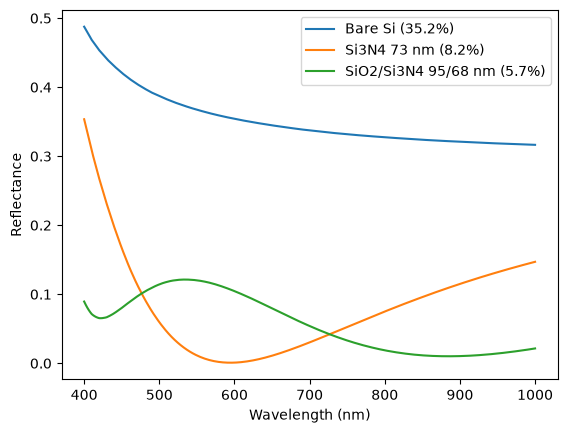

In [74]:
R_single = [coh_tmm('s', [1, n_SiN(w), n_Si(w)], [np.inf, res.x, np.inf], 0, w)['R'] for w in wl]
R_double = [coh_tmm('s', [1, n_SiO2(w), n_SiN(w), n_Si(w)], [np.inf, *res2.x, np.inf], 0, w)['R'] for w in wl]
plt.plot(wl, R_bare, label='Bare Si (35.2%)')
plt.plot(wl, R_single, label=f'Si3N4 {res.x:.0f} nm (8.2%)')
plt.plot(wl, R_double, label=f'SiO2/Si3N4 {res2.x[0]:.0f}/{res2.x[1]:.0f} nm (5.7%)')
plt.xlabel('Wavelength (nm)'); plt.ylabel('Reflectance'); plt.legend(); plt.show()

In [75]:
print('wl,k' in open('data/TiO2_Zhukovsky2015.csv').read())


True


In [ ]:
### SiO2/TiO2
Based on this, I replace Si3N4 with the higher-index TiO2 (n ≈ 2.41). The formula predicts the
center bump should drop to about 3%. The simulation confirms this, and the average reflectance
drops to 2.1% (97.7/56.2 nm).

In [76]:
tio2_n, tio2_k = load_nk('data/TiO2_Zhukovsky2015.csv')

def n_TiO2(wl_nm):
    wl_um = wl_nm / 1000
    return np.interp(wl_um, tio2_n[:, 0], tio2_n[:, 1]) + 1j * np.interp(wl_um, tio2_k[:, 0], tio2_k[:, 1])

def avg_R3(d):
    d1, d2 = d
    return np.mean([coh_tmm('s', [1, n_SiO2(w), n_TiO2(w), n_Si(w)], [np.inf, d1, d2, np.inf], 0, w)['R'] for w in wl])

res3 = minimize(avg_R3, x0=[95, 58], bounds=[(0, 250), (0, 250)], method='L-BFGS-B')
print(f"SiO2: {res3.x[0]:.1f} nm, TiO2: {res3.x[1]:.1f} nm, average R: {res3.fun:.3f}")

SiO2: 97.7 nm, TiO2: 56.2 nm, average R: 0.021


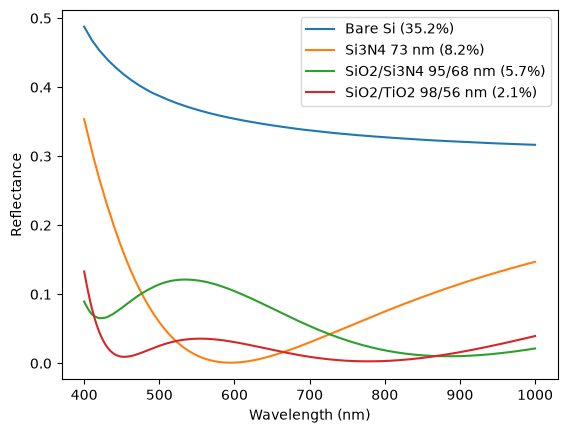

In [77]:
R_single = [coh_tmm('s', [1, n_SiN(w), n_Si(w)], [np.inf, res.x, np.inf], 0, w)['R'] for w in wl]
R_double = [coh_tmm('s', [1, n_SiO2(w), n_SiN(w), n_Si(w)], [np.inf, *res2.x, np.inf], 0, w)['R'] for w in wl]
plt.plot(wl, R_bare, label='Bare Si (35.2%)')
plt.plot(wl, R_single, label=f'Si3N4 {res.x:.0f} nm (8.2%)')
plt.plot(wl, R_double, label=f'SiO2/Si3N4 {res2.x[0]:.0f}/{res2.x[1]:.0f} nm (5.7%)')
R_tio2 = [coh_tmm('s', [1, n_SiO2(w), n_TiO2(w), n_Si(w)], [np.inf, *res3.x, np.inf], 0, w)['R'] for w in wl]
plt.plot(wl, R_tio2, label=f'SiO2/TiO2 {res3.x[0]:.0f}/{res3.x[1]:.0f} nm ({res3.fun*100:.1f}%)')
plt.xlabel('Wavelength (nm)'); plt.ylabel('Reflectance'); plt.legend(); plt.show()

In [ ]:
### Absorption in TiO2 and energy conservation
Since TiO2 absorbs at short wavelengths, low reflectance alone does not guarantee that light
reaches the silicon. TiO2 absorbs about 2% at 400 nm and practically nothing above 450 nm,
so the effect is small. As a consistency check, R + T = 1 holds to ~1e-15 for the non-absorbing
SiO2/Si3N4 stack.

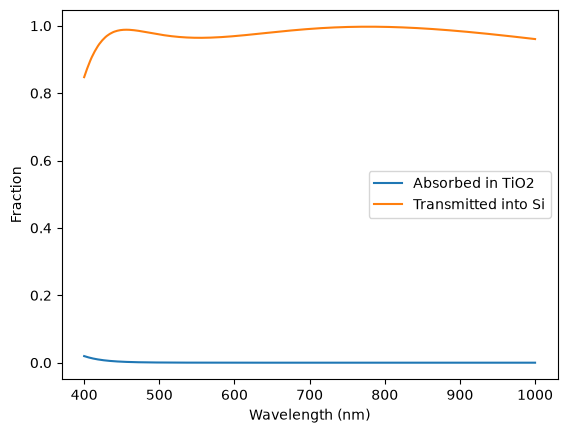

In [78]:
def layer_absorption(w):
    result = coh_tmm('s', [1, n_SiO2(w), n_TiO2(w), n_Si(w)], [np.inf, *res3.x, np.inf], 0, w)
    return absorp_in_each_layer(result)

A = np.array([layer_absorption(w) for w in wl])
plt.plot(wl, A[:, 2], label='Absorbed in TiO2')
plt.plot(wl, A[:, 3], label='Transmitted into Si')
plt.xlabel('Wavelength (nm)'); plt.ylabel('Fraction'); plt.legend(); plt.show()

In [79]:
def check_RT(w):
    r = coh_tmm('s', [1, n_SiO2(w), n_SiN(w), n_Si(w)], [np.inf, *res2.x, np.inf], 0, w)
    return r['R'] + r['T'] - 1

print(np.max(np.abs([check_RT(w) for w in wl])))

1.3322676295501878e-15


In [ ]:
## 5. Own transfer-matrix implementation

I implemented the characteristic-matrix method (Hecht, Macleod) for normal incidence.
Each layer with index $n_j$ and thickness $d_j$ is described by

$$M_j = \begin{pmatrix} \cos\delta_j & -\frac{i}{n_j}\sin\delta_j \\ -i n_j \sin\delta_j & \cos\delta_j \end{pmatrix},
\qquad \delta_j = \frac{2\pi n_j d_j}{\lambda}$$

The total matrix is the product of all layers. With $(B, C)^T = M\,(1, n_s)^T$, the reflection
coefficient is $r = (n_0 B - C)/(n_0 B + C)$ and $R = |r|^2$.

Validation: the code matches the `tmm` package to ~1e-15 for R, T and absorption in all designs,
a zero-thickness layer gives the bare-Si result, and an ideal quarter-wave layer gives R = 0.
It also runs about 2.8× faster for this normal-incidence problem.

In [80]:
def layer_matrix(n, d, wl):
    """2x2 characteristic matrix for one layer at normal incidence."""
    delta = 2 * np.pi * n * d / wl
    return np.array([[np.cos(delta), -1j * np.sin(delta) / n],
                     [-1j * n * np.sin(delta), np.cos(delta)]],
                    dtype=complex)

def stack_matrix(n_list, d_list, wl):
    """Product of all layer matrices, front to back."""
    M = np.eye(2, dtype=complex)
    for n, d in zip(n_list, d_list):
        M = M @ layer_matrix(n, d, wl)
    return M

def my_RT(n_list, d_list, n_sub, wl, n0=1.0):
    """Reflectance and transmittance at normal incidence."""
    M = stack_matrix(n_list, d_list, wl)
    B, C = M @ np.array([1.0, n_sub], dtype=complex)
    r = (n0 * B - C) / (n0 * B + C)
    t = 2 * n0 / (n0 * B + C)
    R = abs(r) ** 2
    T = abs(t) ** 2 * (n_sub.real / n0)   # n0 real here
    return R, T

def my_R(n_list, d_list, n_sub, wl, n0=1.0):
    return my_RT(n_list, d_list, n_sub, wl, n0)[0]

In [81]:
def compare(layers, d_list):
    errs = []
    for w in wl:
        n_list = [f(w) for f in layers]
        R, T = my_RT(n_list, d_list, n_Si(w), w)
        ref = coh_tmm('s', [1, *n_list, n_Si(w)], [np.inf, *d_list, np.inf], 0, w)
        errs.append(max(abs(R - ref['R']), abs(T - ref['T'])))
    return max(errs)

# Test 1: match tmm (R and T) for all three designs
print(compare([n_SiN], [res.x]))
print(compare([n_SiO2, n_SiN], list(res2.x)))
print(compare([n_SiO2, n_TiO2], list(res3.x)))

# Test 2: zero-thickness coating = bare Si
print(my_R([2.0], [0], n_Si(600), 600) - my_R([], [], n_Si(600), 600))

# Test 3: ideal quarter-wave layer on n_s = 4 gives R = 0
print(my_R([2.0], [600 / (4 * 2.0)], 4.0, 600))

1.3322676295501878e-15
1.4432899320127035e-15
1.9984014443252818e-15
0.0
2.109037194368237e-33


In [82]:
loss = []
for w in wl:
    R, T = my_RT([n_SiO2(w), n_TiO2(w)], list(res3.x), n_Si(w), w)
    loss.append(1 - R - T)

print(np.max(np.abs(np.array(loss) - (A[:, 1] + A[:, 2]))))

1.887379141862766e-15


In [83]:
def avg_R3_mine(d):
    return np.mean([my_R([n_SiO2(w), n_TiO2(w)], list(d), n_Si(w), w) for w in wl])

res3_mine = minimize(avg_R3_mine, x0=[95, 58], bounds=[(0, 250), (0, 250)], method='L-BFGS-B')
print(f"SiO2: {res3_mine.x[0]:.1f} nm, TiO2: {res3_mine.x[1]:.1f} nm, average R: {res3_mine.fun:.3f}")

SiO2: 97.7 nm, TiO2: 56.2 nm, average R: 0.021


In [84]:
%timeit avg_R3(res3.x)
%timeit avg_R3_mine(res3.x)

13.4 ms ± 155 μs per loop (mean ± std. dev. of 7 runs, 100 loops each)
4.62 ms ± 25.8 μs per loop (mean ± std. dev. of 7 runs, 100 loops each)


In [ ]:
## 6. Solar-spectrum weighting

So far all wavelengths were weighted equally. For a solar cell, what matters is the number of
photons entering the silicon. I therefore weight by the AM1.5G spectrum (ASTM G173, via pvlib),
converted to photon flux, and minimize the photon-weighted loss $1 - T$, which also counts
absorption in the coating as a loss.

Note: this is a different figure of merit than the average reflectance used above.

Results: the Si3N4 and SiO2/TiO2 designs barely change. The SiO2/Si3N4 design changes completely
(64.2/58.7 nm): instead of the W-shaped spectrum, it now has a single broad dip near the photon-flux
peak (~690 nm) and accepts higher reflection in the blue, where there are fewer photons.
On the solar metric, this reduces the loss from 5.96% to 5.43%. A multi-start check from four
starting points always gives the same optimum.

In [85]:
from pvlib.spectrum import get_reference_spectra
spec = get_reference_spectra()
print(spec.head())

            extraterrestrial        global        direct
wavelength                                              
280.0                  0.082  4.730900e-23  2.536100e-26
280.5                  0.099  1.230700e-21  1.091700e-24
281.0                  0.150  5.689500e-21  6.125300e-24
281.5                  0.212  1.566200e-19  2.747900e-22
282.0                  0.267  1.194600e-18  2.834600e-21


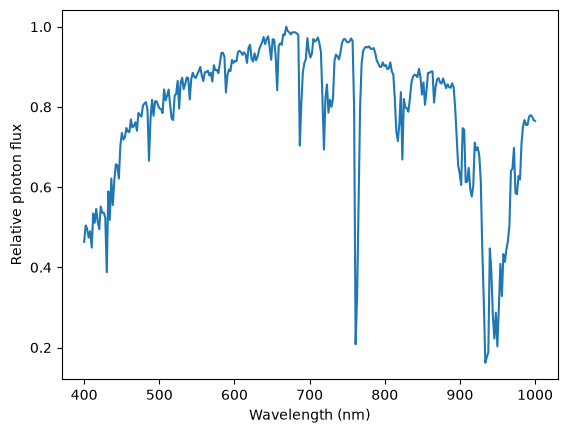

In [86]:
am15 = np.interp(wl, spec.index, spec['global'])   # W/m²/nm on your grid
photons = am15 * wl                                # ∝ photon flux
weights = photons / photons.sum()

plt.plot(wl, photons / photons.max())
plt.xlabel('Wavelength (nm)'); plt.ylabel('Relative photon flux'); plt.show()

In [87]:
def solar_loss(d, layers):
    loss = 0
    for w, wt in zip(wl, weights):
        R, T = my_RT([f(w) for f in layers], list(d), n_Si(w), w)
        loss += wt * (1 - T)
    return loss

opt_SiN = minimize(solar_loss, x0=[73], args=([n_SiN],), bounds=[(0, 250)], method='L-BFGS-B')
opt_SiO2_SiN = minimize(solar_loss, x0=[95, 68], args=([n_SiO2, n_SiN],), bounds=[(0, 250)] * 2, method='L-BFGS-B')
opt_SiO2_TiO2 = minimize(solar_loss, x0=[98, 56], args=([n_SiO2, n_TiO2],), bounds=[(0, 250)] * 2, method='L-BFGS-B')

for name, o in [('Si3N4', opt_SiN), ('SiO2/Si3N4', opt_SiO2_SiN), ('SiO2/TiO2', opt_SiO2_TiO2)]:
    print(f"{name}: {np.round(o.x, 1)} nm, solar-weighted loss: {o.fun:.3f}")

Si3N4: [74.3] nm, solar-weighted loss: 0.071
SiO2/Si3N4: [64.2 58.7] nm, solar-weighted loss: 0.054
SiO2/TiO2: [97.2 57. ] nm, solar-weighted loss: 0.020


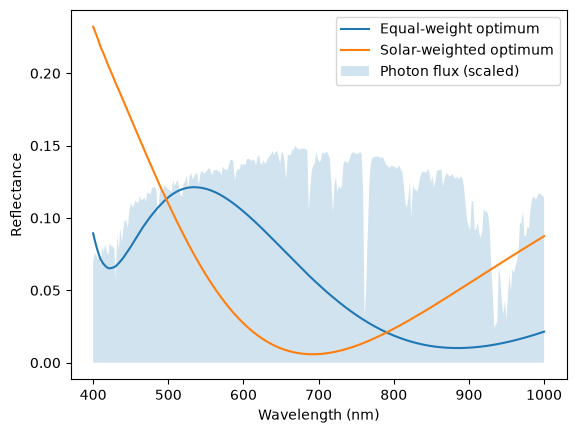

In [88]:
R_eq = [my_R([n_SiO2(w), n_SiN(w)], list(res2.x), n_Si(w), w) for w in wl]
R_sol = [my_R([n_SiO2(w), n_SiN(w)], list(opt_SiO2_SiN.x), n_Si(w), w) for w in wl]
plt.plot(wl, R_eq, label='Equal-weight optimum')
plt.plot(wl, R_sol, label='Solar-weighted optimum')
plt.fill_between(wl, 0, 0.15 * photons / photons.max(), alpha=0.2, label='Photon flux (scaled)')
plt.xlabel('Wavelength (nm)'); plt.ylabel('Reflectance'); plt.legend(); plt.show()

In [89]:
# How does the equal-weight design score on the solar metric?
print(solar_loss(res2.x, [n_SiO2, n_SiN]))

# Multi-start: does the solar optimizer find other minima?
for x0 in [[95, 68], [60, 60], [130, 40], [30, 90]]:
    o = minimize(solar_loss, x0=x0, args=([n_SiO2, n_SiN],), bounds=[(0, 250)] * 2, method='L-BFGS-B')
    print(x0, np.round(o.x, 1), round(o.fun, 4))

0.05964092944347867
[95, 68] [64.2 58.7] 0.0543
[60, 60] [64.  58.6] 0.0543
[130, 40] [64.1 58.6] 0.0543
[30, 90] [64.  58.7] 0.0543


In [ ]:
## 7. Angle dependence

Sunlight does not always hit the cell at normal incidence. Using `tmm` (my implementation covers
normal incidence only), I calculate the solar-weighted loss for unpolarized light (average of s and p)
from 0° to 80°.

All coatings stay stable up to about 40–50° and lose performance quickly above that.
SiO2/TiO2 is the best design at every angle. At 80°, the Si3N4 coating even performs slightly worse
than bare silicon, partly because the effective phase thickness of the layer shrinks at oblique
incidence and shifts the reflection minimum to shorter wavelengths.

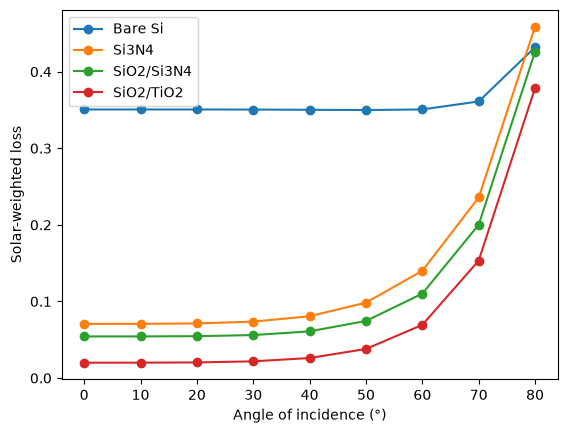

In [90]:
def solar_loss_angle(d, layers, theta_deg):
    th = np.radians(theta_deg)
    loss = 0
    for w, wt in zip(wl, weights):
        n_list = [1, *[f(w) for f in layers], n_Si(w)]
        d_full = [np.inf, *d, np.inf]
        T = 0.5 * (coh_tmm('s', n_list, d_full, th, w)['T'] + coh_tmm('p', n_list, d_full, th, w)['T'])
        loss += wt * (1 - T)
    return loss

angles = np.arange(0, 81, 10)
designs = [('Bare Si', [], []),
           ('Si3N4', [n_SiN], list(opt_SiN.x)),
           ('SiO2/Si3N4', [n_SiO2, n_SiN], list(opt_SiO2_SiN.x)),
           ('SiO2/TiO2', [n_SiO2, n_TiO2], list(opt_SiO2_TiO2.x))]

for name, layers, d in designs:
    plt.plot(angles, [solar_loss_angle(d, layers, a) for a in angles], marker='o', label=name)
plt.xlabel('Angle of incidence (°)'); plt.ylabel('Solar-weighted loss'); plt.legend(); plt.show()

In [ ]:
## 8. Conclusions

- A single Si3N4 layer reduces reflection losses by about a factor of four (35% → 8%).
- Thin-film theory correctly predicted the limitation of SiO2/Si3N4 and the improvement with TiO2.
- The best design, SiO2/TiO2, loses only about 2% of the solar photons at normal incidence.
- The optimal design depends on the figure of merit: solar weighting changes the best SiO2/Si3N4 design completely.
- Possible next steps: extend the wavelength range to the Si band edge (~1100 nm), include
  encapsulation (glass/EVA), and model textured surfaces.